In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the Excel dataset
df = pd.read_excel('/content/Custom_Retail_Sales_Revenue_Dataset.xlsx')

# Display the first 5 rows
df.head()

,Order ID,Order Date,Ship Date,Customer ID,Customer Name,City,State,Region,Segment,Product ID,...,Sub-Category,Quantity,Unit Price (INR),Discount %,Gross Sales (INR),Discount Amount (INR),Revenue (INR),Cost (INR),Profit (INR),Payment Mode
0,ORD1124,2025-01-02,2025-01-07,C002,BlueSky Solutions,Jaipur,Rajasthan,North,Corporate,P012,...,Paper,1,249.0,0.10,249.0,24.90,224.10,95,129.10,UPI
1,ORD1124,2025-01-02,2025-01-06,C002,BlueSky Solutions,Jaipur,Rajasthan,North,Corporate,P015,...,Paper,3,699.0,0.10,2097.0,209.70,1887.30,1230,657.30,UPI
2,ORD1027,2025-01-05,2025-01-09,C013,PixelPoint,Kolkata,West Bengal,East,Corporate,P010,...,Apparel,4,1499.0,0.15,5996.0,899.40,5096.60,3120,1976.60,Cash
3,ORD1027,2025-01-05,2025-01-06,C013,PixelPoint,Kolkata,West Bengal,East,Corporate,P007,...,Desks,1,8999.0,0.05,8999.0,449.95,8549.05,6100,2449.05,Cash
4,ORD1027,2025-01-05,2025-01-08,C013,PixelPoint,Kolkata,West Bengal,East,Corporate,P001,...,Accessories,4,799.0,0.10,3196.0,319.60,2876.40,1560,1316.40,Cash


In [2]:
# Check dataset size
print("Dataset Shape:", df.shape)

# Check column names and data types
print("\nDataset Information:")
df.info()

# Check for missing values
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (286, 22)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 286 entries, 0 to 285
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Order ID               286 non-null    object        
 1   Order Date             286 non-null    datetime64[ns]
 2   Ship Date              286 non-null    datetime64[ns]
 3   Customer ID            286 non-null    object        
 4   Customer Name          286 non-null    object        
 5   City                   286 non-null    object        
 6   State                  286 non-null    object        
 7   Region                 286 non-null    object        
 8   Segment                286 non-null    object        
 9   Product ID             286 non-null    object        
 10  Product Name           286 non-null    object        
 11  Category               286 non-null    object        
 12  Sub-Category     

In [3]:
# Find the earliest and latest order dates
print("First Order Date:", df['Order Date'].min())
print("Last Order Date:", df['Order Date'].max())

# Count unique order dates
print("Unique Order Dates:", df['Order Date'].nunique())

# Check total revenue
print("Total Revenue (INR):", df['Revenue (INR)'].sum())

First Order Date: 2025-01-02 00:00:00
Last Order Date: 2026-10-31 00:00:00
Unique Order Dates: 132
Total Revenue (INR): 1627011.9


In [4]:
# Group sales records by month
monthly_sales = (
    df.set_index('Order Date')
      .resample('MS')['Revenue (INR)']
      .sum()
      .reset_index()
)

# Rename columns
monthly_sales.columns = ['Month', 'Revenue']

# Display monthly revenue
print(monthly_sales)

        Month    Revenue
0  2025-01-01  136900.09
1  2025-02-01   72850.56
2  2025-03-01   17919.72
3  2025-04-01  129801.88
4  2025-05-01  150762.88
5  2025-06-01   61849.05
6  2025-07-01   30035.36
7  2025-08-01   83563.61
8  2025-09-01   71583.97
9  2025-10-01   36440.06
10 2025-11-01   41407.87
11 2025-12-01   91768.79
12 2026-01-01   86927.71
13 2026-02-01   57352.39
14 2026-03-01   78284.24
15 2026-04-01   16174.71
16 2026-05-01  123751.05
17 2026-06-01   74310.43
18 2026-07-01   34552.05
19 2026-08-01   41899.88
20 2026-09-01   68772.83
21 2026-10-01  120102.77


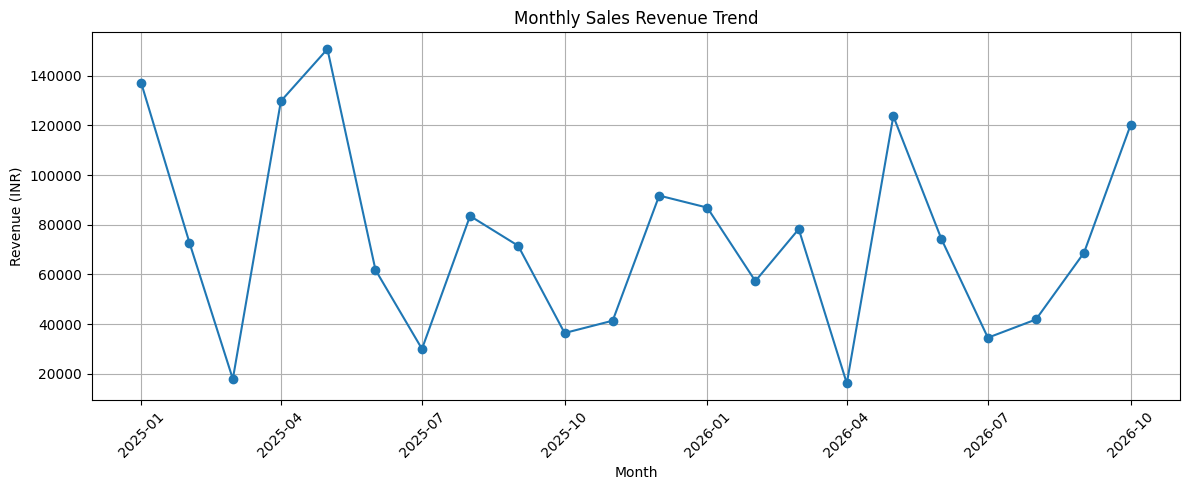

In [5]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['Month'],
    monthly_sales['Revenue'],
    marker='o'
)

plt.title('Monthly Sales Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [6]:
# Create a copy of monthly sales data
model_data = monthly_sales.copy()

# Create a numerical month column
model_data['Month_Number'] = range(len(model_data))

# Split data chronologically
train = model_data.iloc[:18]
test = model_data.iloc[18:]

# Display the split
print("Training Records:", len(train))
print("Testing Records:", len(test))

print("\nTraining Period:")
print(train[['Month', 'Revenue']])

print("\nTesting Period:")
print(test[['Month', 'Revenue']])

Training Records: 18
Testing Records: 4

Training Period:
        Month    Revenue
0  2025-01-01  136900.09
1  2025-02-01   72850.56
2  2025-03-01   17919.72
3  2025-04-01  129801.88
4  2025-05-01  150762.88
5  2025-06-01   61849.05
6  2025-07-01   30035.36
7  2025-08-01   83563.61
8  2025-09-01   71583.97
9  2025-10-01   36440.06
10 2025-11-01   41407.87
11 2025-12-01   91768.79
12 2026-01-01   86927.71
13 2026-02-01   57352.39
14 2026-03-01   78284.24
15 2026-04-01   16174.71
16 2026-05-01  123751.05
17 2026-06-01   74310.43

Testing Period:
        Month    Revenue
18 2026-07-01   34552.05
19 2026-08-01   41899.88
20 2026-09-01   68772.83
21 2026-10-01  120102.77


In [7]:
from sklearn.linear_model import LinearRegression

# Select input (X) and output (y)
X_train = train[['Month_Number']]
y_train = train['Revenue']

X_test = test[['Month_Number']]
y_test = test['Revenue']

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Display model details
print("Model Training Completed!")

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Model Training Completed!
Slope: -1453.027667698658
Intercept: 87999.86684210526


In [8]:
# Predict revenue for testing data
y_pred = model.predict(X_test)

# Compare actual and predicted revenue
results = pd.DataFrame({
    'Month': test['Month'],
    'Actual Revenue': y_test.values,
    'Predicted Revenue': y_pred
})

# Display results
print(results.round(2))

        Month  Actual Revenue  Predicted Revenue
18 2026-07-01        34552.05           61845.37
19 2026-08-01        41899.88           60392.34
20 2026-09-01        68772.83           58939.31
21 2026-10-01       120102.77           57486.29


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Display results
print("MODEL EVALUATION")
print("-------------------------")
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MODEL EVALUATION
-------------------------
MAE: 29558.95
RMSE: 35722.61
R2 Score: -0.1333


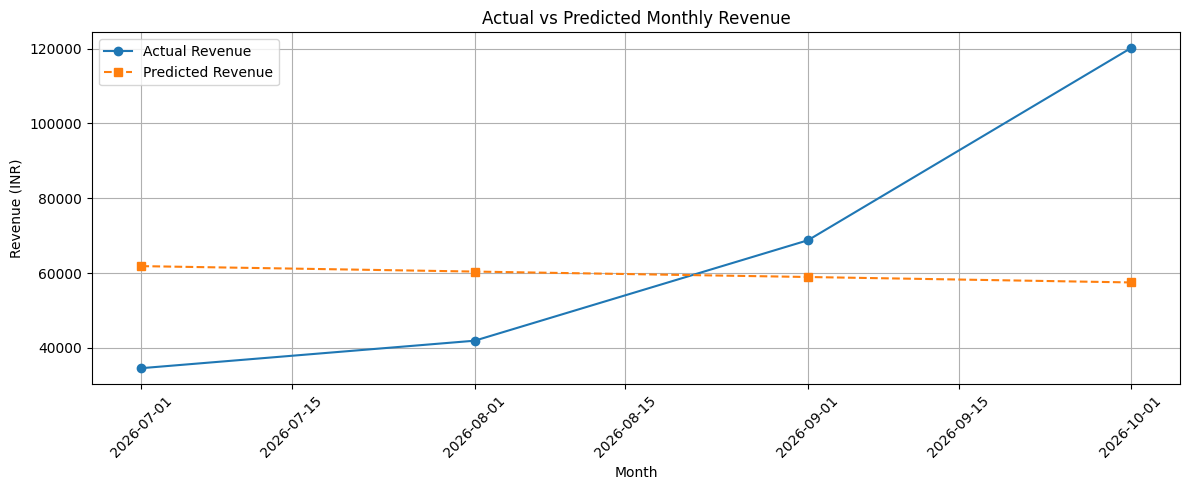

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(
    results['Month'],
    results['Actual Revenue'],
    marker='o',
    label='Actual Revenue'
)

plt.plot(
    results['Month'],
    results['Predicted Revenue'],
    marker='s',
    linestyle='--',
    label='Predicted Revenue'
)

plt.title('Actual vs Predicted Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [11]:
# Create future month numbers
future_months = pd.DataFrame({
    'Month_Number': [22, 23]
})

# Predict future revenue
future_predictions = model.predict(future_months)

# Create future forecast table
future_forecast = pd.DataFrame({
    'Month': pd.date_range(
        start='2026-11-01',
        periods=2,
        freq='MS'
    ),
    'Predicted Revenue': future_predictions
})

print("FUTURE REVENUE FORECAST")
print(future_forecast.round(2))

FUTURE REVENUE FORECAST
       Month  Predicted Revenue
0 2026-11-01           56033.26
1 2026-12-01           54580.23


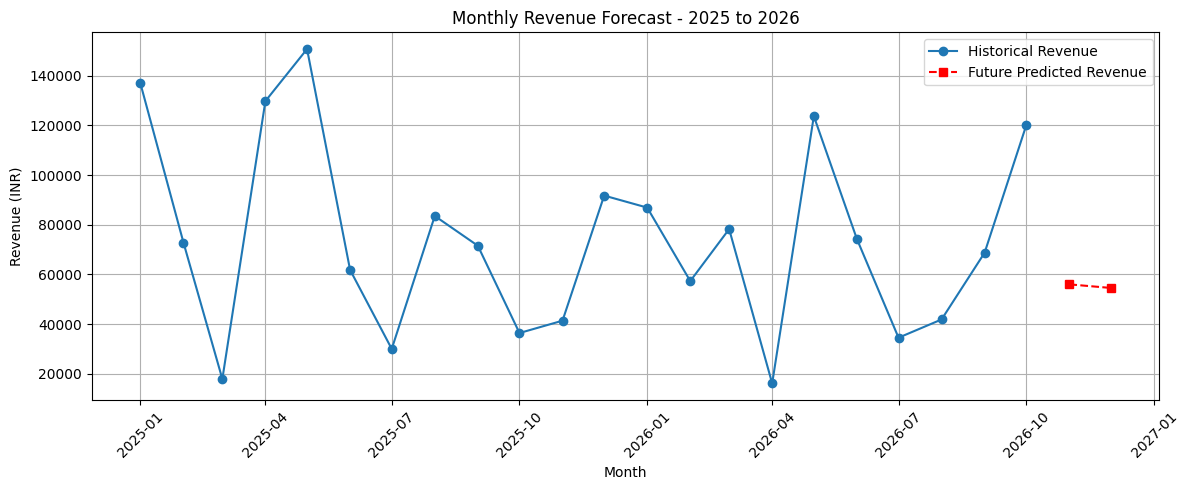

In [12]:
plt.figure(figsize=(12, 5))

# Historical monthly revenue
plt.plot(
    monthly_sales['Month'],
    monthly_sales['Revenue'],
    marker='o',
    label='Historical Revenue'
)

# Future predictions
plt.plot(
    future_forecast['Month'],
    future_forecast['Predicted Revenue'],
    marker='s',
    linestyle='--',
    color='red',
    label='Future Predicted Revenue'
)

plt.title('Monthly Revenue Forecast - 2025 to 2026')
plt.xlabel('Month')
plt.ylabel('Revenue (INR)')
plt.legend()
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

In [13]:
# Save monthly predictions to Excel
future_forecast.to_excel(
    'Future_Revenue_Forecast.xlsx',
    index=False
)

print("Forecast saved successfully!")

Forecast saved successfully!


In [14]:
with pd.ExcelWriter('Complete_Predictive_Analytics_Report.xlsx') as writer:

    # Sheet 1: Historical monthly revenue
    monthly_sales.to_excel(
        writer,
        sheet_name='Monthly Revenue',
        index=False
    )

    # Sheet 2: Actual vs predicted testing data
    results.to_excel(
        writer,
        sheet_name='Model Predictions',
        index=False
    )

    # Sheet 3: Model evaluation
    evaluation = pd.DataFrame({
        'Metric': ['MAE', 'RMSE', 'R2 Score'],
        'Value': [mae, rmse, r2]
    })

    evaluation.to_excel(
        writer,
        sheet_name='Model Evaluation',
        index=False
    )

    # Sheet 4: Future revenue forecast
    future_forecast.to_excel(
        writer,
        sheet_name='Future Forecast',
        index=False
    )

print("Complete Excel Report Created Successfully!")

Complete Excel Report Created Successfully!
